# 06 · Detección de días atípicos

**Entrada:** `data/processed/residuos_PJME.parquet` (residuos fuera de muestra del notebook 04) y, si existe, `tipos_de_dia.parquet` (notebook 05) · **Funciones:** `src/anomalies.py`
**Parámetros:** `src/config.py` (`UMBRAL_Z_MODIFICADO`, `TOLERANCIA_EPISODIO_DIAS`)
**Salida:** `data/processed/anomalias_PJME_diario.parquet`, `anomalias_PJME_lista.parquet` y `anomalias_PJME_episodios.parquet`.

Responde a **P3: ¿qué días se desvían de lo esperable?** Lo esperable es el pronóstico a 24 horas del notebook 04: un día es atípico cuando la demanda real se aleja mucho de lo que el modelo esperaba para ese día, medido solo con predicciones **fuera de muestra**.

**Convención del residuo:** `residuo = real − predicción`. Positivo significa demanda por encima de lo esperable (`alta`) y negativo, por debajo (`baja`).

**Diseño del experimento**

| Elemento | Decisión |
|---|---|
| Unidad | Un día operativo (`Datetime − 1 h`) con sus 24 horas |
| Medida | Residuo medio del día, en % de la predicción media del día (`residuo_pct`), para que sea comparable entre épocas y regiones |
| Regla | z modificado = 0.6745 · (x − mediana) / MAD; atípico si \|z\| > `UMBRAL_Z_MODIFICADO` (3.5, Iglewicz y Hoaglin) |
| Validación | Contraste con episodios externos conocidos (huracán Sandy, vórtices polares, olas de calor), con fuente y verificación |
| Alcance | `PJME`, la región con residuos del notebook 04. Para otras regiones hay que repetir el 04 con cada una |

**Contenido**
1. Configuración y carga
2. Residuo diario
3. z modificado y umbral
4. Lista de días atípicos
5. Línea de tiempo y casos
6. Contraste con episodios conocidos
7. Relación con la forma del día
8. Guardado
9. Resumen y limitaciones

## 1. Configuración y carga

In [1]:
%load_ext autoreload
%autoreload 2

import holidays
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    DESFASE_FIN_DE_HORA, PROCESSED_DIR, TOLERANCIA_EPISODIO_DIAS, UMBRAL_Z_MODIFICADO,
)
from src.features import ESTACIONES
from src.anomalies import (
    CONSTANTE_Z, contrastar_episodios, detectar_atipicos, listar_atipicos,
    residuo_diario, z_modificado,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']

### Parámetros de este notebook

- **`Z_POR_ESTACION`:** con `False`, el z modificado se calcula con todos los días de la región. Si el error del modelo es mayor en invierno que en primavera, los atípicos se concentrarán en invierno (sección 3 lo comprueba). Con `True` se calcula dentro de cada estación, de modo que cada día se compara con los de su misma estación.
- **`N_ANOTADOS` y `N_CASOS`:** días anotados en la línea de tiempo y casos que se dibujan hora a hora.

In [2]:
REGION = 'PJME'
Z_POR_ESTACION = False
N_ANOTADOS = 8
N_CASOS = 4

In [3]:
ruta = PROCESSED_DIR / f"residuos_{REGION}.parquet"
residuos = pd.read_parquet(ruta)

residuos['fecha'] = (residuos['Datetime'] - DESFASE_FIN_DE_HORA).dt.normalize()   # día operativo

print(f"{len(residuos):,} horas · {residuos['Datetime'].min():%Y-%m-%d} → {residuos['Datetime'].max():%Y-%m-%d}")
print("Cada hora aparece una sola vez:", residuos['Datetime'].is_unique)
print("Pliegues:", sorted(residuos['pliegue'].unique()))
residuos.head()

52,584 horas · 2012-08-03 → 2018-08-03
Cada hora aparece una sola vez: True
Pliegues: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


,Datetime,real,prediccion,residuo,pliegue,fecha
0,2012-08-03 01:00:00,34983.0,31643.828125,3339.171875,1,2012-08-03
1,2012-08-03 02:00:00,32651.0,29446.089844,3204.910156,1,2012-08-03
2,2012-08-03 03:00:00,31038.0,28166.806641,2871.193359,1,2012-08-03
3,2012-08-03 04:00:00,30123.0,27566.251953,2556.748047,1,2012-08-03
4,2012-08-03 05:00:00,30089.0,27493.123047,2595.876953,1,2012-08-03


## 2. Residuo diario

`residuo_diario` agrega los residuos horarios por día operativo y conserva solo los días con las 24 horas. El residuo en porcentaje se mide sobre la predicción (lo esperable), no sobre el valor real.

In [4]:
diario = residuo_diario(residuos, region=REGION)

pliegue_dia = residuos.groupby('fecha')['pliegue'].agg(lambda s: s.mode().iloc[0]).rename('pliegue')
diario = diario.merge(pliegue_dia, on='fecha', how='left')

print(f"{len(diario):,} días completos · {diario['fecha'].min():%Y-%m-%d} → {diario['fecha'].max():%Y-%m-%d}")
print("Cada fecha aparece una vez:", diario['fecha'].is_unique)
diario[['residuo_pct', 'residuo_medio_MW', 'residuo_hora_max_MW']].describe().round(2)

Días descartados por tener menos de 24 horas: 0
2,191 días completos · 2012-08-03 → 2018-08-02
Cada fecha aparece una vez: True


,residuo_pct,residuo_medio_MW,residuo_hora_max_MW
count,2191.00,2191.00,2191.00
mean,-0.59,-173.95,3378.92
std,5.54,1822.20,2058.86
min,-27.91,-7969.59,417.33
25%,-3.84,-1166.45,1951.47
50%,-1.00,-301.84,2893.04
75%,2.50,790.31,4224.46
max,25.02,8958.12,15200.15


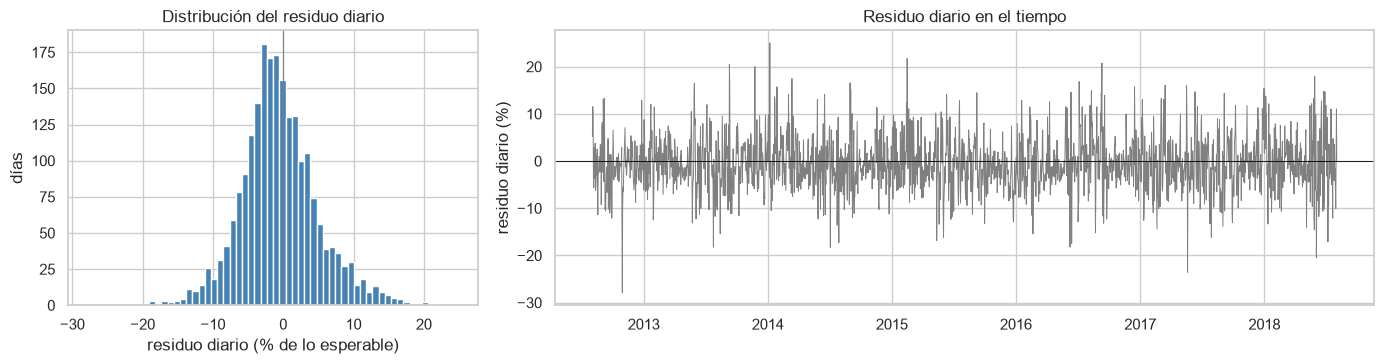

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1, 2]})
axes[0].hist(diario['residuo_pct'], bins=60, color='steelblue')
axes[0].axvline(0, color='gray', linewidth=0.8)
axes[0].set_xlabel('residuo diario (% de lo esperable)')
axes[0].set_ylabel('días')
axes[0].set_title('Distribución del residuo diario')

axes[1].plot(diario['fecha'], diario['residuo_pct'], color='gray', linewidth=0.7)
axes[1].axhline(0, color='black', linewidth=0.6)
axes[1].set_ylabel('residuo diario (%)')
axes[1].set_title('Residuo diario en el tiempo')
plt.tight_layout()
plt.show()

## 3. z modificado y umbral

El z modificado usa la **mediana y la MAD** (mediana de las desviaciones absolutas) en lugar de la media y la desviación estándar, así los propios atípicos no distorsionan la medida. Un día es atípico si su valor absoluto supera `UMBRAL_Z_MODIFICADO`.

In [6]:
marcado = detectar_atipicos(diario)
marcado['anio'] = marcado['fecha'].dt.year
marcado['mes'] = marcado['fecha'].dt.month
marcado['estacion'] = marcado['mes'].map(ESTACIONES)

if Z_POR_ESTACION:
    marcado['z_mod'] = marcado.groupby('estacion')['residuo_pct'].transform(z_modificado)
    marcado['es_atipico'] = marcado['z_mod'].abs() > UMBRAL_Z_MODIFICADO
    marcado['direccion'] = pd.Series(pd.NA, index=marcado.index, dtype='object')
    marcado.loc[marcado['es_atipico'] & (marcado['z_mod'] > 0), 'direccion'] = 'alta'
    marcado.loc[marcado['es_atipico'] & (marcado['z_mod'] < 0), 'direccion'] = 'baja'
    print(f"z modificado por estación: {int(marcado['es_atipico'].sum())} días atípicos")

print(marcado['direccion'].value_counts().rename('días'))

Días atípicos: 22 de 2191 (1.0 %)
direccion
alta    15
baja     7
Name: días, dtype: int64


### 3.1 Sensibilidad al umbral

Cuántos días se marcan con otros umbrales. Si el número cambia mucho entre 3.5 y 4, el criterio de corte es frágil y hay que decirlo.

,umbral,dias_atipicos,pct_dias
0,3.0,52,2.37
1,3.5,22,1.00
2,4.0,9,0.41
3,5.0,2,0.09


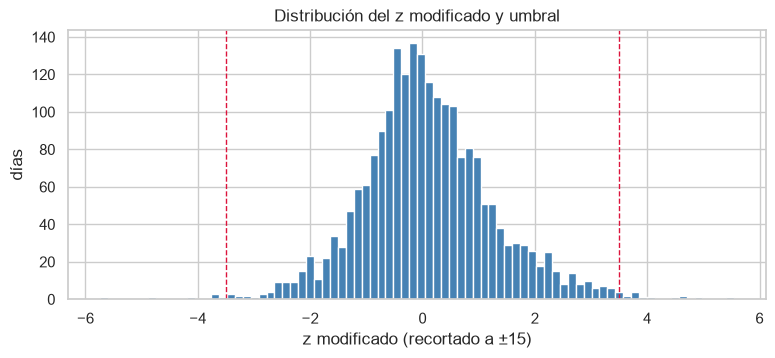

In [7]:
z = marcado['z_mod'].abs()
sensibilidad = pd.DataFrame({
    'umbral': [3.0, 3.5, 4.0, 5.0],
}).assign(
    dias_atipicos=lambda d: [int((z > u).sum()) for u in d['umbral']],
    pct_dias=lambda d: d['dias_atipicos'] / len(z) * 100,
)
display(sensibilidad.round(2))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(marcado['z_mod'].clip(-15, 15), bins=80, color='steelblue')
for s in (-UMBRAL_Z_MODIFICADO, UMBRAL_Z_MODIFICADO):
    ax.axvline(s, color='crimson', linestyle='--', linewidth=1)
ax.set_xlabel('z modificado (recortado a ±15)')
ax.set_ylabel('días')
ax.set_title('Distribución del z modificado y umbral')
plt.show()

### 3.2 ¿Los atípicos se concentran en alguna estación o pliegue?

Si el error del modelo no es homogéneo (por ejemplo, más alto en invierno, o mayor en los primeros pliegues que entrenan con menos historia), los atípicos reflejarán esa diferencia y no solo días raros.

In [8]:
print("Atípicos por estación")
por_estacion = marcado.groupby('estacion').agg(
    dias=('fecha', 'size'), atipicos=('es_atipico', 'sum'),
    mediana_pct=('residuo_pct', 'median'),
    MAD_pct=('residuo_pct', lambda s: (s - s.median()).abs().median()),
)
por_estacion['pct_atipicos'] = por_estacion['atipicos'] / por_estacion['dias'] * 100
display(por_estacion.round(2))

print("Atípicos por pliegue")
por_pliegue = marcado.groupby('pliegue').agg(
    dias=('fecha', 'size'), atipicos=('es_atipico', 'sum'),
    mediana_pct=('residuo_pct', 'median'),
    MAD_pct=('residuo_pct', lambda s: (s - s.median()).abs().median()),
)
por_pliegue['pct_atipicos'] = por_pliegue['atipicos'] / por_pliegue['dias'] * 100
display(por_pliegue.round(2))

Atípicos por estación


,dias,atipicos,mediana_pct,MAD_pct,pct_atipicos
estacion,,,,,
Invierno,541,4,-0.70,3.78,0.74
Otoño,546,5,-1.01,2.47,0.92
Primavera,552,6,-1.30,2.69,1.09
Verano,552,7,-0.89,3.85,1.27


Atípicos por pliegue


,dias,atipicos,mediana_pct,MAD_pct,pct_atipicos
pliegue,,,,,
1,365,3,-1.09,2.89,0.82
2,365,7,-1.01,3.54,1.92
3,365,2,-0.65,3.12,0.55
4,366,3,-1.74,2.68,0.82
5,365,5,-0.96,3.24,1.37
6,365,2,-0.78,3.51,0.55


**Lectura.** Un `MAD_pct` mucho mayor en una estación o pliegue indica que su error es más disperso. Si pasa, probar `Z_POR_ESTACION = True` y comparar la lista de la sección 4. **Conclusión:** `[completar]`

## 4. Lista de días atípicos

`listar_atipicos` ordena los días marcados de mayor a menor magnitud (\|z\|). Se añade el día de la semana y si es festivo federal, porque son las explicaciones de calendario más simples para un día raro.

In [9]:
lista = listar_atipicos(marcado)

anios = range(int(marcado['fecha'].dt.year.min()), int(marcado['fecha'].dt.year.max()) + 1)
festivos = pd.to_datetime(list(holidays.country_holidays('US', years=anios).keys()))

lista['dia_semana'] = lista['fecha'].dt.dayofweek.map(dict(enumerate(DIAS)))
lista['es_festivo'] = lista['fecha'].isin(festivos)
marcado['es_festivo'] = marcado['fecha'].isin(festivos)

print(f"{len(lista)} días atípicos de {len(marcado):,} ({len(lista) / len(marcado):.1%})")
lista[['fecha', 'dia_semana', 'es_festivo', 'direccion', 'residuo_pct', 'residuo_medio_MW',
       'residuo_hora_max_MW', 'z_mod']].head(20).round({'residuo_pct': 2, 'residuo_medio_MW': 2, 'residuo_hora_max_MW': 2, 'z_mod': 2})

22 días atípicos de 2,191 (1.0%)


,fecha,dia_semana,es_festivo,direccion,residuo_pct,residuo_medio_MW,residuo_hora_max_MW,z_mod
0,2012-10-30,Mar,False,baja,-27.91,-7722.94,11487.17,-5.74
1,2014-01-07,Mar,False,alta,25.02,8958.12,12443.58,5.55
2,2015-02-15,Dom,False,alta,21.73,7322.86,9229.63,4.85
3,2017-05-20,Sáb,False,baja,-23.56,-7969.59,15200.15,-4.81
4,2016-09-10,Sáb,False,alta,20.75,7042.55,11772.46,4.64
5,2013-09-10,Mar,False,alta,20.47,6368.34,13488.91,4.58
6,2013-11-24,Dom,False,alta,20.01,5515.01,6770.27,4.48
7,2018-06-03,Dom,False,baja,-20.49,-6641.35,12519.10,-4.16
8,2018-05-29,Mar,False,alta,17.95,5032.09,10743.71,4.04
9,2014-03-13,Jue,False,alta,17.47,5377.30,6706.32,3.94


In [10]:
tasa = marcado.groupby('es_festivo')['es_atipico'].agg(dias='size', atipicos='sum', tasa='mean')
tasa['tasa'] = tasa['tasa'] * 100
print("Tasa de atípicos (%) en festivos y no festivos")
tasa.round(2)

Tasa de atípicos (%) en festivos y no festivos


,dias,atipicos,tasa
es_festivo,,,
False,2126,21,0.99
True,65,1,1.54


## 5. Línea de tiempo y casos

La banda azul es el rango que no se marca como atípico (mediana ± umbral × MAD / 0.6745, solo cuando el z se calcula con todos los días). Los puntos resaltados son los atípicos: naranja si la demanda superó lo esperable y verde si quedó por debajo. Se anotan los de mayor magnitud.

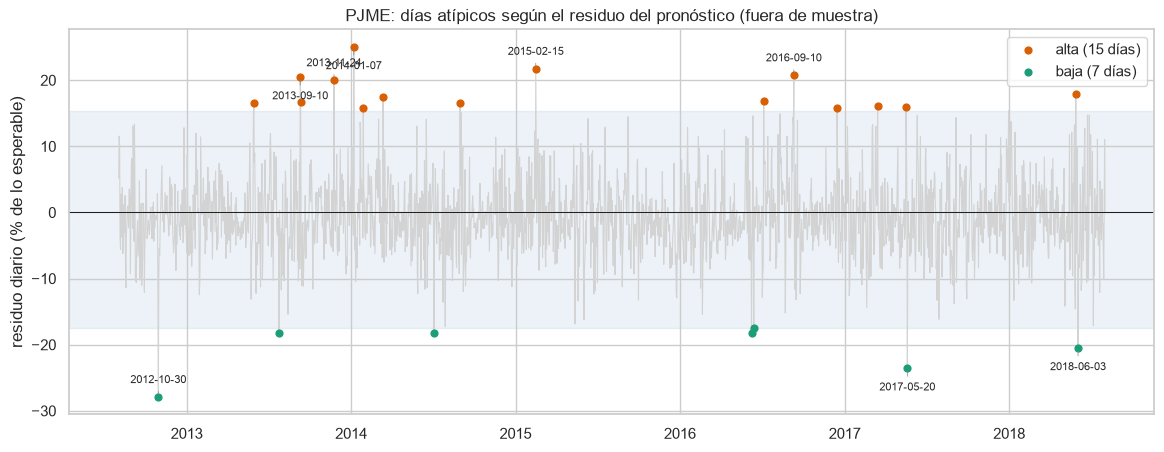

In [11]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(marcado['fecha'], marcado['residuo_pct'], color='lightgray', linewidth=0.8, zorder=1)

if not Z_POR_ESTACION:
    med = marcado['residuo_pct'].median()
    mad = (marcado['residuo_pct'] - med).abs().median()
    lim = UMBRAL_Z_MODIFICADO * mad / CONSTANTE_Z
    ax.axhspan(med - lim, med + lim, color='steelblue', alpha=0.10, zorder=0)

for direccion, color in [('alta', '#d95f02'), ('baja', '#1b9e77')]:
    s = marcado[marcado['direccion'] == direccion]
    ax.scatter(s['fecha'], s['residuo_pct'], color=color, s=24, zorder=3,
               label=f"{direccion} ({len(s)} días)")

for i, fila in enumerate(lista.head(N_ANOTADOS).itertuples()):
    ax.annotate(f"{fila.fecha:%Y-%m-%d}", (fila.fecha, fila.residuo_pct),
                xytext=(0, 10 if i % 2 == 0 else -16), textcoords='offset points',
                ha='center', fontsize=8, arrowprops=dict(arrowstyle='-', color='gray', linewidth=0.5))

ax.axhline(0, color='black', linewidth=0.6)
ax.set_ylabel('residuo diario (% de lo esperable)')
ax.set_title(f'{REGION}: días atípicos según el residuo del pronóstico (fuera de muestra)')
ax.legend(loc='upper right')
plt.show()

### Los casos principales, hora a hora

Real y pronóstico en los días de mayor magnitud, con una ventana de ±3 días. La franja marca el día atípico.

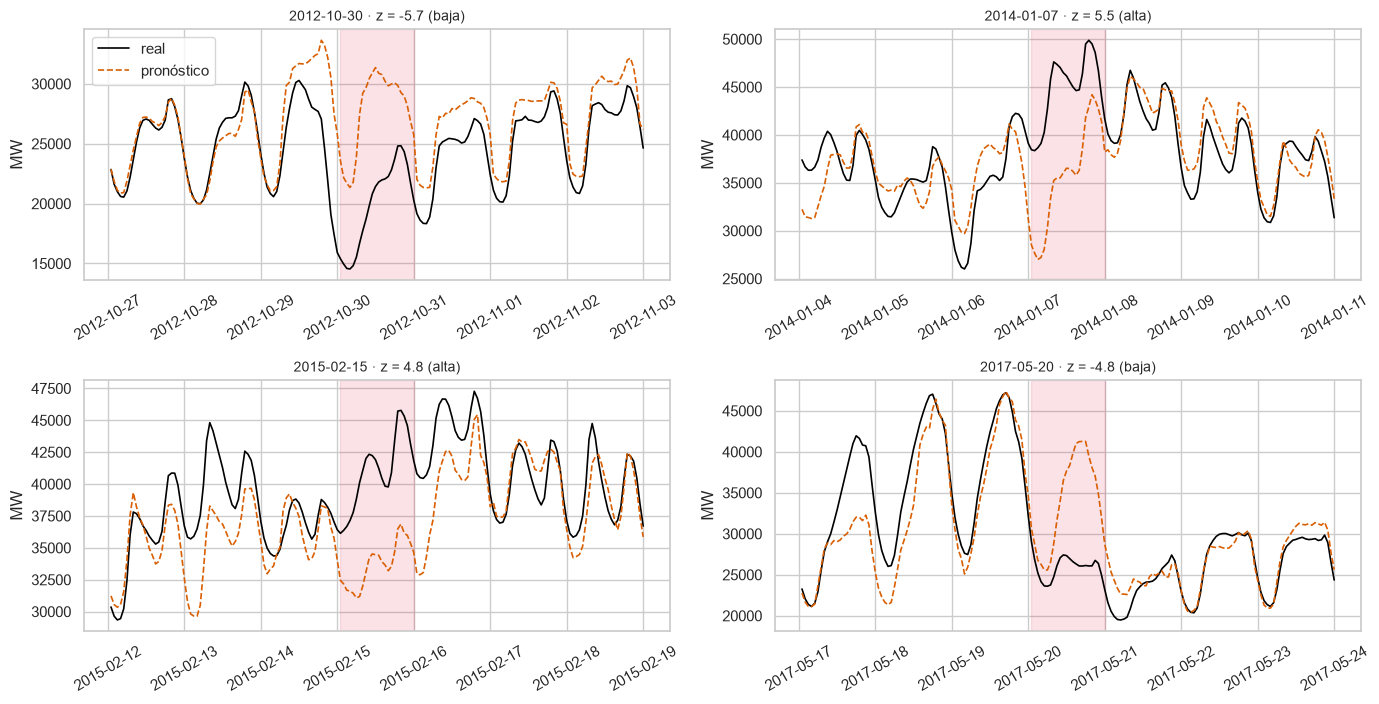

In [12]:
casos = lista.head(N_CASOS)
ncols = 2
nrows = int(np.ceil(len(casos) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.6 * nrows), squeeze=False)

for ax, fila in zip(axes.flat, casos.itertuples()):
    ventana = residuos[(residuos['fecha'] >= fila.fecha - pd.Timedelta(days=3)) &
                       (residuos['fecha'] <= fila.fecha + pd.Timedelta(days=3))]
    ax.plot(ventana['Datetime'], ventana['real'], color='black', linewidth=1.2, label='real')
    ax.plot(ventana['Datetime'], ventana['prediccion'], color='#d95f02', linestyle='--', linewidth=1.2, label='pronóstico')
    ax.axvspan(fila.fecha + pd.Timedelta(hours=1), fila.fecha + pd.Timedelta(days=1), color='crimson', alpha=0.12)
    ax.set_title(f"{fila.fecha:%Y-%m-%d} · z = {fila.z_mod:.1f} ({fila.direccion})", fontsize=10)
    ax.tick_params(axis='x', rotation=30)
    ax.set_ylabel('MW')
axes.flat[0].legend()
for ax in axes.flat[len(casos):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Interpretación.** `[completar]` (qué ocurrió en los días principales y si el patrón es de demanda por encima o por debajo de lo esperable).

## 6. Contraste con episodios conocidos

Un detector de anomalías solo es creíble si encuentra eventos que se conocen por otra vía. Se contrasta cada episodio con los días atípicos, con un margen de `TOLERANCIA_EPISODIO_DIAS` días. Los episodios fuera del rango cubierto por los residuos se marcan como **fuera de rango** (no evaluados), distinto de **sin coincidencia** (evaluados y no detectados).

Cada episodio lleva su `fuente` y si sus fechas están `verificado`. Las fechas se tomaron de fuentes públicas (PJM, NERC, EIA, prensa especializada); las que no tienen fuente deben verificarse antes de citarlas en el informe. La tabla de este notebook reemplaza a `EPISODIOS_CONOCIDOS` de `src/anomalies.py`, que no incluye fuentes: conviene actualizar ese archivo con la misma tabla.

In [13]:
EPISODIOS = pd.DataFrame([
    ("Ola de calor de agosto de 2006 (récord de PJM el 2 de agosto)", "2006-08-01", "2006-08-03", "calor extremo", "alta",
     "https://www.spglobal.com/energy/en/news-research/latest-news/electric-power/031325-ceraweek-fercs-christie-calls-the-need-for-more-gas-fired-power-a-rendezvous-with-reality", True),
    ("Ola de calor de julio de 2011", "2011-07-20", "2011-07-22", "calor extremo", "alta",
     "https://www.spglobal.com/energy/en/news-research/latest-news/electric-power/031325-ceraweek-fercs-christie-calls-the-need-for-more-gas-fired-power-a-rendezvous-with-reality", True),
    ("Huracán Sandy", "2012-10-29", "2012-10-31", "evento climático", "baja",
     "https://www.eia.gov/todayinEnergy/detail.php?id=8750", True),
    ("Ola de calor de julio de 2013 (pico de PJM el 18 de julio)", "2013-07-15", "2013-07-19", "calor extremo", "alta",
     "https://greentechmedia.com/amp/article/mo-money-mo-demand-response", True),
    ("Calor de septiembre de 2013", "2013-09-10", "2013-09-12", "calor extremo", "alta",
     "https://greentechmedia.com/amp/article/demand-response-hits-a-new-record-in-pjm", True),
    ("Vórtice polar de enero de 2014 (récord invernal del 7)", "2014-01-06", "2014-01-08", "frío extremo", "alta",
     "https://www.nerc.com/pa/rrm/ea/ColdWeatherTrainingMaterials/2015_Winter_Review_December_2015_FINAL.pdf", True),
    ("Vórtice polar de fines de enero de 2014", "2014-01-23", "2014-01-29", "frío extremo", "alta",
     "https://www.witf.org/2018/01/05/heating_bills_spike_like_its_the_polar_vortex_of_january_2014/", True),
    ("Ola de frío de febrero de 2015 (récord invernal del 20)", "2015-02-14", "2015-02-21", "frío extremo", "alta",
     "https://www.nerc.com/pa/rrm/ea/ColdWeatherTrainingMaterials/2015_Winter_Review_December_2015_FINAL.pdf", True),
    ("Tormenta Jonas", "2016-01-22", "2016-01-24", "evento climático", "por verificar",
     "", False),
    ("Ola de frío de enero de 2018", "2018-01-01", "2018-01-07", "frío extremo", "alta",
     "https://www.witf.org/2018/01/05/heating_bills_spike_like_its_the_polar_vortex_of_january_2014/", True),
], columns=["episodio", "inicio", "fin", "tipo", "direccion_esperada", "fuente", "verificado"])
EPISODIOS['inicio'] = pd.to_datetime(EPISODIOS['inicio'])
EPISODIOS['fin'] = pd.to_datetime(EPISODIOS['fin'])

contraste = contrastar_episodios(
    lista, EPISODIOS,
    fecha_min=marcado['fecha'].min(), fecha_max=marcado['fecha'].max(),
)

margen = pd.Timedelta(days=TOLERANCIA_EPISODIO_DIAS)

def direcciones_detectadas(ep):
    dentro = lista[(lista['fecha'] >= ep['inicio'] - margen) & (lista['fecha'] <= ep['fin'] + margen)]
    return ', '.join(sorted(dentro['direccion'].dropna().unique()))

def coincide_direccion(ep):
    if ep['estado'] != 'coincide' or ep['direccion_esperada'] not in ('alta', 'baja'):
        return ''
    return 'Sí' if ep['direccion_esperada'] in ep['direccion_detectada'].split(', ') else 'No'

contraste['direccion_detectada'] = contraste.apply(direcciones_detectadas, axis=1)
contraste['coincide_direccion'] = contraste.apply(coincide_direccion, axis=1)

print(f"Rango cubierto por los residuos: {marcado['fecha'].min():%Y-%m-%d} → {marcado['fecha'].max():%Y-%m-%d}")
print(contraste['estado'].value_counts().to_string())
contraste[['episodio', 'inicio', 'fin', 'estado', 'n_dias_atipicos', 'max_abs_z', 'fechas',
           'direccion_esperada', 'direccion_detectada', 'coincide_direccion', 'verificado']].round({'max_abs_z': 2})

Rango cubierto por los residuos: 2012-08-03 → 2018-08-02
estado
coincide            5
sin coincidencia    3
fuera de rango      2


,episodio,inicio,fin,estado,n_dias_atipicos,max_abs_z,fechas,direccion_esperada,direccion_detectada,coincide_direccion,verificado
0,Ola de calor de agosto de 2006 (récord de PJM ...,2006-08-01,2006-08-03,fuera de rango,0,NaN,,alta,,,True
1,Ola de calor de julio de 2011,2011-07-20,2011-07-22,fuera de rango,0,NaN,,alta,,,True
2,Huracán Sandy,2012-10-29,2012-10-31,coincide,1,5.74,2012-10-30,baja,baja,Sí,True
3,Ola de calor de julio de 2013 (pico de PJM el ...,2013-07-15,2013-07-19,sin coincidencia,0,NaN,,alta,,,True
4,Calor de septiembre de 2013,2013-09-10,2013-09-12,coincide,2,4.58,"2013-09-10, 2013-09-11",alta,alta,Sí,True
5,Vórtice polar de enero de 2014 (récord inverna...,2014-01-06,2014-01-08,coincide,1,5.55,2014-01-07,alta,alta,Sí,True
6,Vórtice polar de fines de enero de 2014,2014-01-23,2014-01-29,coincide,1,3.57,2014-01-28,alta,alta,Sí,True
7,Ola de frío de febrero de 2015 (récord inverna...,2015-02-14,2015-02-21,coincide,1,4.85,2015-02-15,alta,alta,Sí,True
8,Tormenta Jonas,2016-01-22,2016-01-24,sin coincidencia,0,NaN,,por verificar,,,False
9,Ola de frío de enero de 2018,2018-01-01,2018-01-07,sin coincidencia,0,NaN,,alta,,,True


**Cómo leer la tabla.** `coincide` significa que al menos un día atípico cae dentro del episodio (± tolerancia). `direccion_detectada` es el signo de esos días y `coincide_direccion` indica si es el esperado: un frío o calor extremo debería dar residuos positivos (más demanda de la esperable) y Sandy, negativos (la demanda cayó por los cortes de luz). Un episodio sin coincidencia no se oculta: si el modelo ya anticipaba bien el frío o el calor (porque rezagos y medias móviles lo incorporan), el día no sale atípico aunque haya sido extremo.

**Criterio de cierre:** lista contrastada con al menos un episodio externo. `[completar]`

### 6.1 Atípicos sin episodio conocido

Los días marcados que no caen en ningún episodio de la tabla. Sin temperatura en el dataset no se puede confirmar el clima de estos días; se listan como candidatos a revisar (festivos, cambios de horario, eventos locales).

In [14]:
def en_episodio(fecha):
    return bool(((EPISODIOS['inicio'] - margen <= fecha) & (fecha <= EPISODIOS['fin'] + margen)).any())

lista['en_episodio'] = lista['fecha'].map(en_episodio)
sin_episodio = lista[~lista['en_episodio']]
print(f"{len(sin_episodio)} de {len(lista)} atípicos no coinciden con ningún episodio de la tabla")
sin_episodio[['fecha', 'dia_semana', 'es_festivo', 'direccion', 'residuo_pct', 'z_mod']].head(15).round({'residuo_pct': 2, 'z_mod': 2})

16 de 22 atípicos no coinciden con ningún episodio de la tabla


,fecha,dia_semana,es_festivo,direccion,residuo_pct,z_mod
3,2017-05-20,Sáb,False,baja,-23.56,-4.81
4,2016-09-10,Sáb,False,alta,20.75,4.64
6,2013-11-24,Dom,False,alta,20.01,4.48
7,2018-06-03,Dom,False,baja,-20.49,-4.16
8,2018-05-29,Mar,False,alta,17.95,4.04
9,2014-03-13,Jue,False,alta,17.47,3.94
10,2016-07-05,Mar,False,alta,16.85,3.81
12,2014-08-31,Dom,False,alta,16.56,3.74
13,2013-05-30,Jue,False,alta,16.49,3.73
14,2014-07-04,Vie,True,baja,-18.27,-3.68


**Interpretación.** `[completar]` (qué episodios se detectan y cuáles no, si el signo coincide con el esperado, y qué tipo de días quedan sin explicar).

## 7. Relación con la forma del día

El notebook 05 mide cuánto se aleja la **forma** de cada día de la de su tipo (`distancia_centroide`), mientras que este notebook mide cuánto se aleja el **nivel** de lo pronosticado. Un día puede ser raro en una, en la otra o en ambas. Esta sección solo corre si existe `tipos_de_dia.parquet`.

In [15]:
ruta_tipos = PROCESSED_DIR / "tipos_de_dia.parquet"
if ruta_tipos.exists():
    tipos = pd.read_parquet(ruta_tipos)
    tipos = tipos[tipos['region'] == REGION][['fecha', 'grupo', 'nombre_grupo', 'distancia_centroide']]
    cruce = marcado.merge(tipos, on='fecha', how='left')
    cruce['z_abs'] = cruce['z_mod'].abs()

    print(f"Días con tipo de día: {cruce['grupo'].notna().sum():,} de {len(cruce):,}")
    print("Correlación de Spearman entre |z| y la distancia al centro del grupo:",
          round(cruce[['z_abs', 'distancia_centroide']].corr(method='spearman').iloc[0, 1], 2))

    corte = cruce['distancia_centroide'].quantile(0.95)
    print(f"\nAtípico por residuo (filas) frente a forma lejana, percentil 95 de la distancia (columnas)")
    display(pd.crosstab(cruce['es_atipico'], cruce['distancia_centroide'] > corte))

    print("Atípicos por tipo de día")
    display(cruce.groupby('nombre_grupo')['es_atipico'].agg(dias='size', atipicos='sum', tasa='mean').round(3))
else:
    print("No existe tipos_de_dia.parquet: ejecutar antes el notebook 05.")

Días con tipo de día: 2,191 de 2,191
Correlación de Spearman entre |z| y la distancia al centro del grupo: 0.02

Atípico por residuo (filas) frente a forma lejana, percentil 95 de la distancia (columnas)


distancia_centroide,False,True
es_atipico,,
False,2067,102
True,14,8


Atípicos por tipo de día


,dias,atipicos,tasa
nombre_grupo,,,
G1 · Invierno · mixto,1350,11,0.008
G2 · Verano · mixto,841,11,0.013


**Interpretación.** `[completar]` (si los días atípicos por nivel también tienen una forma inusual, o si son días de forma normal pero con más o menos demanda).

## 8. Guardado

| Archivo | Contenido |
|---|---|
| `anomalias_PJME_diario.parquet` | Todos los días con residuo, z modificado, marca de atípico y dirección (contexto completo para la línea de tiempo del panel) |
| `anomalias_PJME_lista.parquet` | Solo los días atípicos, de mayor a menor magnitud |
| `anomalias_PJME_episodios.parquet` | Contraste con los episodios, con fuente y verificación |

In [16]:
columnas = ['region', 'fecha', 'anio', 'mes', 'estacion', 'pliegue', 'horas', 'real_medio_MW',
            'prediccion_media_MW', 'residuo_medio_MW', 'residuo_pct', 'residuo_hora_max_MW',
            'z_mod', 'es_atipico', 'direccion', 'es_festivo']
diario_out = marcado[columnas]

lista_out = lista[['region', 'fecha', 'dia_semana', 'es_festivo', 'direccion', 'residuo_pct',
                   'residuo_medio_MW', 'residuo_hora_max_MW', 'z_mod', 'en_episodio']]

archivos = {
    f'anomalias_{REGION}_diario.parquet': diario_out,
    f'anomalias_{REGION}_lista.parquet': lista_out,
    f'anomalias_{REGION}_episodios.parquet': contraste,
}
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
for nombre, tabla in archivos.items():
    tabla.to_parquet(PROCESSED_DIR / nombre, index=False)
    print(f"{nombre}: {len(tabla):,} filas")

anomalias_PJME_diario.parquet: 2,191 filas
anomalias_PJME_lista.parquet: 22 filas
anomalias_PJME_episodios.parquet: 10 filas


## 9. Resumen y limitaciones

### Resultados

| Indicador | Valor |
|---|---|
| Región | `PJME` |
| Periodo cubierto por los residuos |  (6 pliegues de 12 meses) |
| Días evaluados |  |
| Días atípicos (z modificado > 3.5) |  ( % de los días,  altos y  bajos) |
| Sensibilidad al umbral |  |
| Episodios con coincidencia |  |
| Coincidencia de la dirección |  |

### Días atípicos principales

| Fecha | Dirección | Residuo (%) | z | Episodio |
|---|---|---|---|---|
|  |  |  |  |  |

**Interpretación:** 

### Criterios de cierre

### Limitaciones

- **Sin temperatura.** Es el principal determinante de la demanda y el dataset no la incluye, así que los días atípicos se interpretan por coincidencia con eventos y no por su causa. Un día extremo por clima puede no salir atípico si los rezagos y medias móviles del modelo ya lo incorporaban.
- **Lo atípico depende del modelo.** Un modelo mejor o peor cambia los residuos y, con ellos, la lista. El residuo mide cuánto se desvía la demanda de lo que este pronóstico esperaba.
- **Una sola región.** Los residuos son de `PJME`; para otras regiones hay que repetir el notebook 04 con cada una.
- **Cobertura temporal.** Los residuos cubren los últimos seis años; los episodios anteriores (2006, 2011) quedan fuera de rango y no se evalúan.
- **Residuos de pliegues con menos historia.** Los primeros pliegues entrenan con menos datos, y su error puede ser algo mayor (sección 3.2).
- **Umbral convencional.** El 3.5 es el valor de Iglewicz y Hoaglin para el z modificado; no garantiza una tasa de falsos positivos concreta, por eso se muestra la sensibilidad.
- **Días de cambio de horario.** Tienen una hora estimada o promediada en la limpieza; si resultan atípicos, hay que descartar ese efecto.
- **Festivos federales.** Los festivos usados son los federales de EE. UU.; los de cada estado no están incluidos.
